In [ ]:
# simplified version of ~/analysis/run12/data/plotting/052725_efficiency_corrected_batch50000.ipynb
# stochastic uncertainties: 1) statistical, 2) seed, 3) MC bootstrap, 4) data bootstrap
# only included 1) and 2) - but only have one seed as an example
# systematic uncertainties: none included

In [ ]:
import numpy as np
from matplotlib import pyplot as plt
import matplotlib.gridspec as gridspec
import pandas as pd
import uproot
import glob

In [46]:
warnings.resetwarnings()

In [2]:
def applyCut(inputDataframe, cut):
    dataframe = inputDataframe
    cutDataframe = dataframe.query(cut)
    return cutDataframe

In [3]:
def getData(observables, filename):
    return (uproot.open(filename)["MatchedTree"]).arrays(observables, library='pd')

In [48]:
# add new columns 'a' and 'loga' to dataframe
def addNewBranches(inputDataframe):
    df_temp = inputDataframe.copy()
    df_temp.eval('a=(m*m-mg*mg)/(pt*pt)', inplace=True)
    df_temp['a'] = df_temp['a'].mask(df_temp['a'] < 1e-4, 7.9e-5)
    df_temp.eval('loga=log10(a)', inplace=True)
    return df_temp

In [ ]:
def get_eff(ob, binedges, truth_cut, file=None):
    if file is None:
        file = inputFiles[0]
    df = applyCut(addNewBranches(getData(observables+observabless, file)), truth_cut)
    match_miss, _ = np.histogram(df[ob], bins=binedges, weights=df['w'])
    match, _ = np.histogram(df[(df.pts>15)&(df.w<5e-9)][ob], bins=binedges, weights=df[(df.pts>15)&(df.w<5e-9)]['w'])
    return match/(1e-50+match_miss)

In [6]:
def calc_hist_nonuniform(vals, bins, weights, density=False):
    if weights is None:
        weights = np.ones(vals.shape)
    hist, bins = np.histogram(vals, bins=bins, weights=weights)
    digits = np.digitize(vals, bins)
    errs = np.asarray([np.linalg.norm(weights[digits==i]) for i in range(1, len(bins))])
    for i in range(1, len(bins)):
        hist[i-1] /= (bins[i] - bins[i-1])
        errs[i-1] /= (bins[i] - bins[i-1])       
    if density:
        hist /= weights.sum()
        errs /= weights.sum()   
    return hist, errs, bins

# Read in prior

In [49]:
observables = ['pt','q','m','rg','zg','mg','w']
observabless = ['pts']#,'qs','ms','rgs','zgs','mgs']
inputFiles = ['/nfs/roberts/home/ys668/output/run12/all050124_rc_notrueptcons.root',\
             '/nfs/roberts/home/ys668/output/run12/all050124_rc_eff096_notrueptcons.root',\
             '/nfs/roberts/home/ys668/output/run12/all050124_rc_tow104_notrueptcons.root',\
             '/nfs/roberts/home/ys668/output/run12/all050124_rc_hadcorr05_notrueptcons.root']
df1 = applyCut(getData(observables+observabless, inputFiles[0]), 'pt>0 and pts>0 and w<5e-9')
df1 = addNewBranches(df1)

In [18]:
df1

,pt,q,m,rg,zg,mg,w,pts,a,loga
63,22.269343,-0.116126,4.720392,0.203809,0.189784,3.486002,1.335866e-10,24.310953,2.042631e-02,-1.689810
135,13.327448,0.482896,5.602998,0.255045,0.225147,5.602998,1.335866e-10,18.980080,-5.000417e-16,NaN
288,15.950633,0.221033,4.089250,0.375994,0.152818,4.089250,1.335866e-10,15.322203,2.373850e-16,-15.624547
424,11.627170,0.289864,4.260939,0.380580,0.284170,4.260939,1.335866e-10,17.218631,-3.941880e-16,NaN
669,18.259376,-0.426127,5.963011,0.309819,0.481809,5.963011,1.335866e-10,16.581160,-1.491820e-16,NaN
...,...,...,...,...,...,...,...,...,...,...
21479914,12.440178,0.251657,4.784653,0.322813,0.138609,4.784653,3.372111e-10,15.281649,-5.509577e-16,NaN
21480187,11.145841,-0.931236,3.115816,0.299341,0.289531,3.115816,3.372111e-10,18.721520,-1.000927e-16,NaN
21480861,13.415522,-0.282619,6.646395,0.287769,0.450083,6.347381,3.372111e-10,15.268221,2.158795e-02,-1.665789
21481999,15.122849,0.039113,4.660299,0.286580,0.137786,4.440372,3.372111e-10,18.864532,8.751533e-03,-2.057916


# Read in unfolded

In [19]:
for it in range(1,9):
    filelist = glob.glob("/nfs/roberts/scratch/pi_hlc7/ys668/test_101326/it"+str(it)+'_*')
    if (it == 1):
        print("Each iteration has", len(filelist), "trials.")
    for file in filelist:
        df_temp = pd.read_csv(file, low_memory=False)
        seed_id = file.replace('.csv','').split("seed",1)[1]
        column_name = "w_it" + str(it) + "_seed" + seed_id
        df1[column_name] = np.asarray(df_temp['weight'])

Each iteration has 1 trials.


In [45]:
df1 # new columns are results (weights) from different iterations and different seeds (trials) (for this example, only had 1 trial)

,pt,q,m,rg,zg,mg,w,pts,a,loga,w_it1_seed1,w_it2_seed1,w_it3_seed1,w_it4_seed1,w_it5_seed1,w_it6_seed1,w_it7_seed1,w_it8_seed1
63,22.269343,-0.116126,4.720392,0.203809,0.189784,3.486002,1.335866e-10,24.310953,2.042631e-02,-1.689810,0.000006,0.000006,0.000006,0.000006,0.000006,0.000006,0.000006,0.000006
135,13.327448,0.482896,5.602998,0.255045,0.225147,5.602998,1.335866e-10,18.980080,-5.000417e-16,NaN,0.000006,0.000006,0.000006,0.000006,0.000006,0.000006,0.000006,0.000006
288,15.950633,0.221033,4.089250,0.375994,0.152818,4.089250,1.335866e-10,15.322203,2.373850e-16,-15.624547,0.000005,0.000005,0.000005,0.000005,0.000005,0.000004,0.000004,0.000004
424,11.627170,0.289864,4.260939,0.380580,0.284170,4.260939,1.335866e-10,17.218631,-3.941880e-16,NaN,0.000005,0.000005,0.000005,0.000005,0.000005,0.000005,0.000005,0.000005
669,18.259376,-0.426127,5.963011,0.309819,0.481809,5.963011,1.335866e-10,16.581160,-1.491820e-16,NaN,0.000005,0.000005,0.000005,0.000005,0.000005,0.000005,0.000005,0.000005
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21479914,12.440178,0.251657,4.784653,0.322813,0.138609,4.784653,3.372111e-10,15.281649,-5.509577e-16,NaN,0.000013,0.000013,0.000013,0.000013,0.000013,0.000013,0.000013,0.000013
21480187,11.145841,-0.931236,3.115816,0.299341,0.289531,3.115816,3.372111e-10,18.721520,-1.000927e-16,NaN,0.000013,0.000013,0.000013,0.000013,0.000013,0.000013,0.000013,0.000013
21480861,13.415522,-0.282619,6.646395,0.287769,0.450083,6.347381,3.372111e-10,15.268221,2.158795e-02,-1.665789,0.000014,0.000014,0.000015,0.000015,0.000015,0.000016,0.000016,0.000016
21481999,15.122849,0.039113,4.660299,0.286580,0.137786,4.440372,3.372111e-10,18.864532,8.751533e-03,-2.057916,0.000014,0.000014,0.000014,0.000014,0.000014,0.000014,0.000014,0.000014


# Obtain unfolded distribution and do efficiency correction

In [ ]:
def get_seed_unc(df, it, ob, binedges, seed_string="_seed"):
    ys = []
    rels_stat_err = []
    diff_ys_y = []
    for column_name in df.columns:
        if column_name.startswith("w_it" + str(it) + seed_string):
            ys.append(np.histogram(df[ob], bins=binedges, weights=df[column_name], density=True)[0])
            rels_stat_err.append(np.sqrt(np.histogram(df[ob], bins=binedges, weights=df[column_name]**2, density=False)[0])/\
                                 np.histogram(df[ob], bins=binedges, weights=df[column_name], density=False)[0])
    y = np.median(ys, axis=0)
    y_err = 1.253 * np.std(ys, axis=0) / np.sqrt(len(ys))
    print("relative uncertainty from NN:", y_err/y)
    
    for i in range(len(ys)):
        diff_ys_y.append(abs(ys[i] - y))
    diff_ys_y = np.array(diff_ys_y)   
    y_stat_err = []
    for i in range(len(binedges)-1):
        trial_index = np.where(diff_ys_y[:,i] == min(diff_ys_y[:,i]))[0][0] # for bin i, which seed gives the y closest to the median?
        y_stat_err.append(rels_stat_err[trial_index][i]*y[i])
    print("relative uncertainty from stat:", y_stat_err/y)
    
    return y, y_err, y_stat_err # median over all seeds, uncertainty from different seeds, regular statistical uncertainty

In [34]:
def process_ob_nom(ob_index):
    
    print("observable:", obs[ob_index])
    ob = obs[ob_index]
    binedges = binedgess[ob_index]
    cut = cuts[ob_index]
    
    x = []
    for i in range(0, len(binedges)-1):
        midpoint = 0.5 * (binedges[i] + binedges[i+1])
        x.append(midpoint)
    
    df1_cut = applyCut(df1, cut)
    eff = get_eff(ob, binedges, cut)
    
    y_arr = []
    err_arr = []
    
    for it in range(1,9):
        print("iteration", it)
        y_seed, err_seed, err_stat = get_seed_unc(df1_cut, it, ob, binedges)
        if (it == 102): # this by default should be 2, which is the nominal number of iterations used. haven't done that for this example so i am skipping it by setting it to 102
            y_mc_bs, err_mc_bs = get_mc_bs_unc(df1_cut, it, ob, binedges)
            y_data_bs, err_data_bs = get_data_bs_unc(df1_cut, it, ob, binedges)
        else:
            y_mc_bs = np.ones(len(y_seed))
            err_mc_bs = np.zeros(len(y_seed))
            y_data_bs = np.ones(len(y_seed))
            err_data_bs = np.zeros(len(y_seed))
        rel_err = np.sqrt( (err_stat/y_seed)**2 + (err_seed/y_seed)**2 + (err_mc_bs/y_mc_bs)**2 + (err_data_bs/y_data_bs)**2 )
        print('total (stat + NN + MC bootstrap + data bootstrap):', rel_err)
        err = y_seed * rel_err
        
        # scale by efficiency
        y_scaled = y_seed / (1e-50 + eff)
        err_scaled = err / (1e-50 + eff)
        
        # normalize
        bin_widths = np.diff(binedges)
        y_arr.append(y_scaled / sum(y_scaled) / bin_widths)
        err_arr.append(err_scaled / sum(y_scaled) / bin_widths)

    return x, y_arr, err_arr

# $Q$

In [35]:
obs = ['q','q','q','q','q']
binedgess = [np.arange(-1.0,1.2,0.2),np.arange(-1.0,1.2,0.2),np.arange(-1.0,1.2,0.2),np.arange(-1.0,1.2,0.2),np.arange(-0.8,1.2,0.4)]
cuts = ['20<pt<25', '25<pt<30', '30<pt<40', '40<pt<60', '40<pt<60']

In [36]:
x, y_arr, err_arr = process_ob_nom(0)
# x, y_arr_hw, err_arr_hw = process_ob_hw(0)
# x, y_arr_py8, err_arr_py8 = process_ob_py8(0)
# x, y_arr_eff096, err_arr_eff096 = process_ob_detector(0, "eff096", df1_eff096)
# x, y_arr_tow104, err_arr_tow104 = process_ob_detector(0, "tow104", df1_tow104)
# x, y_arr_hadcorr05, err_arr_hadcorr05 = process_ob_detector(0, "hadcorr05", df1_hadcorr05)

observable: q


iteration 1
relative uncertainty from NN: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
relative uncertainty from stat: [0.01326119 0.00955315 0.00712758 0.00575264 0.0051314  0.00485321
 0.0049345  0.00560826 0.00683903 0.0094985 ]
total (stat + NN + MC bootstrap + data bootstrap): [0.01326119 0.00955315 0.00712758 0.00575264 0.0051314  0.00485321
 0.0049345  0.00560826 0.00683903 0.0094985 ]
iteration 2
relative uncertainty from NN: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
relative uncertainty from stat: [0.01320924 0.00958472 0.00714691 0.00576552 0.00514101 0.00486425
 0.0049473  0.0056255  0.0068388  0.0094779 ]
total (stat + NN + MC bootstrap + data bootstrap): [0.01320924 0.00958472 0.00714691 0.00576552 0.00514101 0.00486425
 0.0049473  0.0056255  0.0068388  0.0094779 ]
iteration 3
relative uncertainty from NN: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
relative uncertainty from stat: [0.01319271 0.00961517 0.00717006 0.00577998 0.0051535  0.00487588
 0.00495993 0.00563954 0.00684484 0.00946696]
total (stat + N

In [37]:
mean_20_25 = y_arr[1]
err_20_25 = err_arr[1]

In [38]:
x, y_arr, err_arr = process_ob_nom(1)

observable: q
iteration 1
relative uncertainty from NN: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
relative uncertainty from stat: [0.01946513 0.01168421 0.00883127 0.00696833 0.00631517 0.00582007
 0.00601217 0.00659732 0.00815324 0.0114029 ]
total (stat + NN + MC bootstrap + data bootstrap): [0.01946513 0.01168421 0.00883127 0.00696833 0.00631517 0.00582007
 0.00601217 0.00659732 0.00815324 0.0114029 ]
iteration 2
relative uncertainty from NN: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
relative uncertainty from stat: [0.01950567 0.01172741 0.00884259 0.00699681 0.00632984 0.0058484
 0.00603494 0.0066227  0.00815303 0.01142463]
total (stat + NN + MC bootstrap + data bootstrap): [0.01950567 0.01172741 0.00884259 0.00699681 0.00632984 0.0058484
 0.00603494 0.0066227  0.00815303 0.01142463]
iteration 3
relative uncertainty from NN: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
relative uncertainty from stat: [0.01959776 0.01177152 0.00886252 0.00702514 0.00634614 0.005874
 0.00605836 0.00665038 0.00816441 0.01144558]
total

In [39]:
mean_25_30 = y_arr[1]
err_25_30 = err_arr[1]

In [40]:
x, y_arr, err_arr = process_ob_nom(2)

observable: q
iteration 1
relative uncertainty from NN: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
relative uncertainty from stat: [0.02553576 0.01602168 0.01138661 0.00882818 0.00755914 0.00693313
 0.00705824 0.00782564 0.00991167 0.01499684]
total (stat + NN + MC bootstrap + data bootstrap): [0.02553576 0.01602168 0.01138661 0.00882818 0.00755914 0.00693313
 0.00705824 0.00782564 0.00991167 0.01499684]
iteration 2
relative uncertainty from NN: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
relative uncertainty from stat: [0.02568666 0.01612312 0.01145215 0.00887534 0.00760642 0.00697078
 0.00709264 0.00784874 0.00993121 0.01503453]
total (stat + NN + MC bootstrap + data bootstrap): [0.02568666 0.01612312 0.01145215 0.00887534 0.00760642 0.00697078
 0.00709264 0.00784874 0.00993121 0.01503453]
iteration 3
relative uncertainty from NN: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
relative uncertainty from stat: [0.02588296 0.01623184 0.01152735 0.00892983 0.00765098 0.00701108
 0.00712036 0.00787589 0.00996228 0.01506254]
t

In [41]:
mean_30_40 = y_arr[1]
err_30_40 = err_arr[1]

In [42]:
x, y_arr, err_arr = process_ob_nom(3)

observable: q
iteration 1
relative uncertainty from NN: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
relative uncertainty from stat: [0.05274563 0.02463762 0.01870492 0.01297029 0.01058615 0.0098813
 0.00868006 0.01028754 0.01420152 0.01915544]
total (stat + NN + MC bootstrap + data bootstrap): [0.05274563 0.02463762 0.01870492 0.01297029 0.01058615 0.0098813
 0.00868006 0.01028754 0.01420152 0.01915544]
iteration 2
relative uncertainty from NN: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
relative uncertainty from stat: [0.0543448  0.0249658  0.019046   0.01336302 0.01075952 0.00996085
 0.00877615 0.01037661 0.01443291 0.0191949 ]
total (stat + NN + MC bootstrap + data bootstrap): [0.0543448  0.0249658  0.019046   0.01336302 0.01075952 0.00996085
 0.00877615 0.01037661 0.01443291 0.0191949 ]
iteration 3
relative uncertainty from NN: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
relative uncertainty from stat: [0.05568968 0.02541592 0.01931384 0.0136068  0.01089322 0.01006569
 0.00883923 0.01041148 0.01441528 0.01916657]
tot

In [43]:
mean_40_60 = y_arr[1]
err_40_60 = err_arr[1]

[Text(0, 0.0, ''),
 Text(0, 0.2, ''),
 Text(0, 0.4, ''),
 Text(0, 0.6000000000000001, ''),
 Text(0, 0.8, ''),
 Text(0, 1.0, ''),
 Text(0, 1.2000000000000002, ''),
 Text(0, 1.4000000000000001, ''),
 Text(0, 1.6, '')]

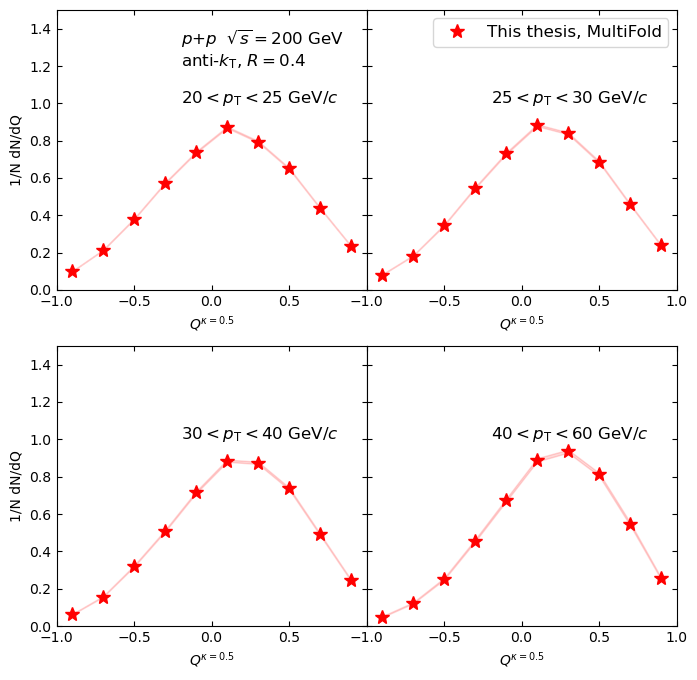

In [44]:
gs1 = gridspec.GridSpec(2,2,width_ratios=(1,1), height_ratios=(5,5))

fig = plt.figure(figsize=(8,8))
plt.subplots_adjust(wspace=0)

binedges = binedgess[0]
x = []
for i in range(0, len(binedges)-1):
    midpoint = 0.5 * (binedges[i] + binedges[i+1])
    x.append(midpoint)

ax1 = fig.add_subplot(gs1[0])
plt.text(-0.2,1.2,'$p$+$p$  $\sqrt{s}=200$ GeV\nanti-$k_\mathrm{T}$, $R=0.4$', fontsize=12)
plt.text(-0.2,1.,'$20 < p_\mathrm{T} < 25$ GeV/$c$', fontsize=12)
plt.plot(x, mean_20_25, color='red', marker='*', ls='none', markersize=10)
plt.fill_between(x, mean_20_25-err_20_25, mean_20_25+err_20_25, color='r', alpha=0.15)
plt.xlim(-1,1)
plt.xlabel('$Q^{\kappa=0.5}$')
plt.ylim(0,1.5)
plt.ylabel('1/N dN/dQ')
ax = plt.gca()
ax.tick_params(top=True, right=True, bottom=True, left=True, direction='in', which='both')
#ax.axes.xaxis.set_minor_locator(MultipleLocator(0.5))
#ax.axes.xaxis.set_major_locator(MultipleLocator(2))
#ax.axes.yaxis.set_minor_locator(MultipleLocator(0.01))
#ax.axes.yaxis.set_major_locator(MultipleLocator(0.05))
plt.xticks(np.arange(-1.,1,0.5))

ax2 = fig.add_subplot(gs1[1])
plt.text(-0.2,1,'$25 < p_\mathrm{T} < 30$ GeV/$c$', fontsize=12)
plt.plot(x, mean_25_30, color='red', marker='*', ls='none', markersize=10, label='This thesis, MultiFold')
plt.fill_between(x, mean_25_30-err_25_30, mean_25_30+err_25_30, color='r', alpha=0.15)
plt.xlim(-1,1)
plt.xlabel('$Q^{\kappa=0.5}$')
plt.ylim(0,1.5)
ax = plt.gca()
ax.tick_params(top=True, right=True, bottom=True, left=True, direction='in', which='both')
ax.axes.yaxis.set_ticklabels([])
#ax.axes.xaxis.set_minor_locator(MultipleLocator(0.5))
#ax.axes.xaxis.set_major_locator(MultipleLocator(2))
#ax.axes.yaxis.set_minor_locator(MultipleLocator(0.01))
#ax.axes.yaxis.set_major_locator(MultipleLocator(0.05))
plt.legend(fontsize=12, loc='upper right')

ax3 = fig.add_subplot(gs1[2])
plt.text(-0.2,1,'$30 < p_\mathrm{T} < 40$ GeV/$c$', fontsize=12)
plt.plot(x, mean_30_40, color='red', marker='*', ls='none', markersize=10)
plt.fill_between(x, mean_30_40-err_30_40, mean_30_40+err_30_40, color='r', alpha=0.15)
plt.xlim(-1,1)
plt.xlabel('$Q^{\kappa=0.5}$')
plt.ylabel('1/N dN/dQ')
plt.ylim(0,1.5)
ax = plt.gca()
ax.tick_params(top=True, right=True, bottom=True, left=True, direction='in', which='both')
#ax.axes.xaxis.set_minor_locator(MultipleLocator(0.5))
#ax.axes.xaxis.set_major_locator(MultipleLocator(2))
#ax.axes.yaxis.set_minor_locator(MultipleLocator(0.01))
#ax.axes.yaxis.set_major_locator(MultipleLocator(0.05))
plt.xticks(np.arange(-1.,1,0.5))

ax4 = fig.add_subplot(gs1[3])
plt.text(-0.2,1,'$40 < p_\mathrm{T} < 60$ GeV/$c$', fontsize=12)
plt.plot(x, mean_40_60, color='red', marker='*', ls='none', markersize=10, label='MultiFold')
plt.fill_between(x, mean_40_60-err_40_60, mean_40_60+err_40_60, color='r', alpha=0.15)
plt.xlim(-1,1)
plt.xlabel('$Q^{\kappa=0.5}$')
plt.ylim(0,1.5)
ax = plt.gca()
ax.tick_params(top=True, right=True, bottom=True, left=True, direction='in', which='both')
ax.axes.yaxis.set_ticklabels([])
#ax.axes.xaxis.set_minor_locator(MultipleLocator(0.5))
#ax.axes.xaxis.set_major_locator(MultipleLocator(2))
#ax.axes.yaxis.set_minor_locator(MultipleLocator(0.01))
#ax.axes.yaxis.set_major_locator(MultipleLocator(0.05))